# Public-data analysis of ARSI resistance in prostate cancer

**Shu Chen — Postdoctoral Scholar, UCSF**

This notebook uses public patient cohorts to examine expression changes associated with metastatic CRPC and prior ARSI exposure. SSTR1 is included as a prespecified gene because it is a focus of my current experimental work.

**Questions**

1. Which genes differ between localized prostate cancer and metastatic CRPC?
2. Which leading signals are likely confounded by specimen composition or tissue handling?
3. Which candidates show a concordant signal in an independent ARSI-exposed mCRPC cohort?
4. Do public data support the direction of the SSTR1 signal?

The final section uses the data-derived results for a small LLM reasoning check. Public data are downloaded on first run and cached in `data/`.


## 1. Setup

Analysis thresholds are defined before candidate review.


In [1]:
from pathlib import Path
import gzip
import io
import json
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
from sklearn.decomposition import PCA
import GEOparse
import gseapy as gp

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, RES, EVAL = ROOT / "data", ROOT / "results", ROOT / "evaluation"
FIG = RES / "figures"
for d in (DATA, RES, FIG, EVAL):
    d.mkdir(parents=True, exist_ok=True)

FDR_MAX = 0.05          # discovery FDR (Benjamini-Hochberg)
LFC_MIN = 1.0           # minimum |difference in mean log2 ratio|
COMPOSITION_RHO = 0.5   # Spearman rho with a composition score (within localized tumors) that flags a gene
N_REPLICATE = 300       # top unflagged hits taken to the replication cohort
REPL_FDR = 0.10         # replication FDR across the genes tested in SU2C
PRESPECIFIED = ["SSTR1"]

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
})
GROUP_COLORS = {"Benign": "#9e9e9e", "Localized": "#3b75af", "CRPC": "#c0392b"}
pd.set_option("display.float_format", "{:.3g}".format)

## 2. Discovery cohort: GSE35988

GSE35988 (Grasso et al., *Nature* 2012) includes benign prostate, localized tumors collected at prostatectomy, and metastatic CRPC collected through a rapid-autopsy program. Only GPL6480 samples are used so all samples are measured on the same array platform.

The processed values are already log2(sample/reference) ratios from two-color Agilent arrays; they are not log-transformed again.


In [2]:
GSE_URL = ("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE35nnn/GSE35988/matrix/"
           "GSE35988-GPL6480_series_matrix.txt.gz")
matrix_file = DATA / "GSE35988-GPL6480_series_matrix.txt.gz"
if not matrix_file.exists():
    urllib.request.urlretrieve(GSE_URL, matrix_file)


def read_series_matrix(path):
    # A series matrix holds per-sample metadata (!Sample_ lines) and then the expression table.
    sample_meta, table, in_table = {}, [], False
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("!series_matrix_table_begin"):
                in_table = True
            elif line.startswith("!series_matrix_table_end"):
                in_table = False
            elif line.startswith("!Sample_"):
                parts = line.rstrip("\n").split("\t")
                sample_meta.setdefault(parts[0][len("!Sample_"):], []).append([x.strip('"') for x in parts[1:]])
            elif in_table:
                table.append(line)

    expr = pd.read_csv(io.StringIO("".join(table)), sep="\t", index_col=0, na_values=["null", "NA", ""])
    expr.index = expr.index.astype(str).str.strip('"')
    expr.columns = expr.columns.astype(str).str.strip('"')
    expr = expr.apply(pd.to_numeric, errors="coerce")

    # keep single-line fields only
    fields = {k: v[0] for k, v in sample_meta.items() if len(v) == 1 and len(v[0]) == expr.shape[1]}
    return expr, pd.DataFrame(fields, index=expr.columns)


expr_probe, meta = read_series_matrix(matrix_file)


def assign_group(row):
    # channel 2 is the tissue sample; channel 1 is the reference
    text = " ".join(str(row.get(c, "")) for c in ["title", "source_name_ch2", "characteristics_ch2"]).lower()
    if "metastatic" in text or "castrate resistant" in text or "castration resistant" in text:
        return "CRPC"
    if "localized prostate cancer" in text:
        return "Localized"
    if "benign prostate" in text:
        return "Benign"
    return "Unknown"


meta["group"] = meta.apply(assign_group, axis=1)
counts = meta["group"].value_counts()
assert counts.to_dict() == {"Localized": 49, "CRPC": 27, "Benign": 12}, counts
print(expr_probe.shape)
print(counts.to_string())

(41000, 88)
group
Localized    49
CRPC         27
Benign       12


### Probe-to-gene mapping

Probes without a gene symbol, with >20% missing values, or with zero variance are removed. When multiple probes map to the same gene, the most variable probe is retained. No absolute-expression filter is applied because these data are expression ratios.


In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore", pd.errors.DtypeWarning)  # mixed types in an unused annotation column
    gpl = GEOparse.get_GEO(geo="GPL6480", destdir=str(DATA), silent=True)
symbol = (gpl.table.assign(ID=lambda d: d["ID"].astype(str))
          .set_index("ID")["GENE_SYMBOL"].astype(str).str.strip()
          .reindex(expr_probe.index))

steps = [("GPL6480 probes", len(expr_probe))]
x = expr_probe[symbol.notna() & ~symbol.isin(["", "nan", "NA", "---"])]
steps.append(("with gene symbol", len(x)))
x = x[x.isna().mean(axis=1) <= 0.20]
steps.append(("missing in <=20% of samples", len(x)))
probe_var = x.var(axis=1)
x = x[probe_var > 1e-8]
steps.append(("non-constant", len(x)))

best_probe = probe_var.loc[x.index].groupby(symbol.loc[x.index]).idxmax()
expr = x.loc[best_probe.values]
expr.index = pd.Index(best_probe.index, name="gene")
steps.append(("genes (most variable probe per gene)", len(expr)))

filter_log = pd.DataFrame(steps, columns=["step", "n"])
filter_log.to_csv(RES / "filter_log.csv", index=False)
filter_log

,step,n
0,GPL6480 probes,41000
1,with gene symbol,30936
2,missing in <=20% of samples,26743
3,non-constant,26743
4,genes (most variable probe per gene),17237


### QC: PCA and reference genes

Mean imputation is used only for PCA. AR, EZH2, and AURKA are inspected as reference genes with established changes in advanced prostate cancer.


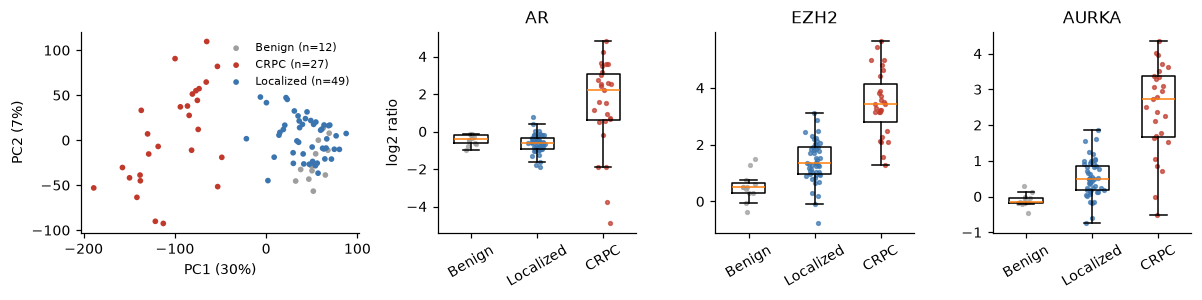

In [4]:
X = expr.T.fillna(expr.T.mean())
pca = PCA(n_components=2, random_state=0)
pcs = pd.DataFrame(pca.fit_transform(X), index=X.index, columns=["PC1", "PC2"]).join(meta["group"])

check = ["AR", "EZH2", "AURKA"]
fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1.4, 1, 1, 1]})
for g, sub in pcs.groupby("group"):
    axes[0].scatter(sub.PC1, sub.PC2, s=14, color=GROUP_COLORS[g], label=f"{g} (n={len(sub)})", edgecolor="none")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
axes[0].legend(frameon=False, fontsize=7)

order = ["Benign", "Localized", "CRPC"]
rng = np.random.default_rng(0)
for ax, gene in zip(axes[1:], check):
    vals = [expr.loc[gene, meta.index[meta.group == g]].dropna() for g in order]
    ax.boxplot(vals, showfliers=False, widths=0.5)
    for i, (g, v) in enumerate(zip(order, vals), start=1):
        ax.scatter(rng.normal(i, 0.06, len(v)), v, s=6, color=GROUP_COLORS[g], alpha=0.7)
    ax.set_xticks([1, 2, 3], order, rotation=30)
    ax.set_title(gene)
axes[1].set_ylabel("log2 ratio")
fig.tight_layout()
fig.savefig(FIG / "01_qc_pca_known_genes.png", bbox_inches="tight")
plt.show()

CRPC and localized samples separate along PC1 with overlap. Benign tissue clusters near localized tumors, consistent with PC1 carrying both disease-related and tissue-composition signal. AR, EZH2, and AURKA are higher in CRPC.

## 3. Differential expression: CRPC vs localized

Welch's t-test is applied gene by gene to log2 ratios, followed by Benjamini-Hochberg correction. Discovery hits require FDR < 0.05 and |log2FC| > 1.


In [5]:
crpc = meta.index[meta.group == "CRPC"]
local = meta.index[meta.group == "Localized"]
a, b = expr[crpc], expr[local]

t = stats.ttest_ind(a, b, axis=1, equal_var=False, nan_policy="omit")
de = pd.DataFrame({
    "n_CRPC": a.notna().sum(axis=1),
    "n_Localized": b.notna().sum(axis=1),
    "mean_CRPC": a.mean(axis=1),
    "mean_Localized": b.mean(axis=1),
    "p": np.ma.filled(np.ma.asarray(t.pvalue, dtype=float), np.nan),
})
de["log2FC"] = de.mean_CRPC - de.mean_Localized
de = de[(de.n_CRPC >= 3) & (de.n_Localized >= 3)].dropna(subset=["p"])
de["FDR"] = multipletests(de.p, method="fdr_bh")[1]
de["hit"] = (de.FDR < FDR_MAX) & (de.log2FC.abs() > LFC_MIN)

print(f"genes tested: {len(de)}")
print(f"hits: {de.hit.sum()}  (up {((de.log2FC > 0) & de.hit).sum()}, down {((de.log2FC < 0) & de.hit).sum()})")
de.sort_values("p").head(12)[["mean_CRPC", "mean_Localized", "log2FC", "FDR"]]

genes tested: 17237
hits: 5746  (up 2119, down 3627)


,mean_CRPC,mean_Localized,log2FC,FDR
gene,,,,
PAGE4,-6.36,0.485,-6.84,2.1e-35
FCER1A,-3.72,0.736,-4.46,1.05e-32
SRD5A2,-5.59,-0.59,-5,5.23e-27
MS4A2,-3.09,1.26,-4.36,5.35e-27
PCP4,-4.08,0.723,-4.81,9.34e-27
ACTG2,-4.48,-0.13,-4.35,1.36e-25
ASB5,-6.74,-0.516,-6.22,1.6e-25
C18orf34,-2.99,0.882,-3.88,1.68e-25
ACTBL2,-3.75,-0.524,-3.23,3.43e-25


Many of the most significant down-regulated genes are known stromal, mast-cell, or immediate-early-response genes. This makes specimen composition and collection method an important confounder in the CRPC-vs-localized contrast.

## 4. Composition and tissue-handling check

Each sample is scored for smooth-muscle stroma, immune cells, mast cells, and immediate-early stress using marker-gene z-scores. A discovery hit is flagged when its expression is strongly associated with one of these scores across localized tumors (Spearman |rho| >= 0.5). When the tested gene is part of a marker set, that gene is omitted from the corresponding score.


In [6]:
SIGNATURES = {
    "stroma": ["ACTG2", "MYH11", "CNN1", "DES", "TAGLN", "ACTA2"],
    "immune": ["PTPRC", "CD3E", "MS4A1", "CD68", "CD163", "LCP2"],
    "mast_cell": ["TPSAB1", "CPA3", "MS4A2", "KIT", "HDC"],
    "early_response": ["FOS", "FOSB", "EGR1", "ATF3", "IER2", "NR4A1", "DUSP1", "ZFP36", "JUNB"],
}
z = expr.sub(expr.mean(axis=1), axis=0).div(expr.std(axis=1), axis=0)


def program_score(genes, drop=None):
    return z.loc[[g for g in genes if g in z.index and g != drop]].mean()


scores = pd.DataFrame({k: program_score(v) for k, v in SIGNATURES.items()})
display(scores.groupby(meta.group).mean().loc[["Benign", "Localized", "CRPC"]].round(2))

loc_expr = expr[local].T
rho = pd.DataFrame({k: loc_expr.corrwith(scores.loc[local, k], method="spearman") for k in SIGNATURES})
for k, genes in SIGNATURES.items():  # leave-one-out for marker genes
    for g in genes:
        if g in loc_expr.columns:
            rho.loc[g, k] = stats.spearmanr(loc_expr[g], program_score(genes, drop=g)[local], nan_policy="omit")[0]

de = de.join(rho.add_prefix("rho_"))
rho_cols = [f"rho_{k}" for k in SIGNATURES]
de["composition_rho"] = de[rho_cols].max(axis=1)
de["composition_driver"] = de[rho_cols].idxmax(axis=1).str.replace("rho_", "")
de["composition_flag"] = de.composition_rho >= COMPOSITION_RHO
de.to_csv(RES / "deg_crpc_vs_localized.csv", index_label="gene")

hits = de[de.hit]
print("hits flagged by composition/handling:")
print(hits.groupby(np.where(hits.log2FC > 0, "up in CRPC", "down in CRPC")).composition_flag.agg(["sum", "count", "mean"]).round(2))
print(hits[hits.composition_flag].composition_driver.value_counts().to_string())

,stroma,immune,mast_cell,early_response
group,,,,
Benign,1.06,-0.39,0.63,0.48
Localized,0.41,0.17,0.56,0.42
CRPC,-1.21,-0.14,-1.3,-0.97


hits flagged by composition/handling:
               sum  count  mean
down in CRPC  1218   3627  0.34
up in CRPC      64   2119  0.03
composition_driver
stroma            582
mast_cell         382
immune            252
early_response     66


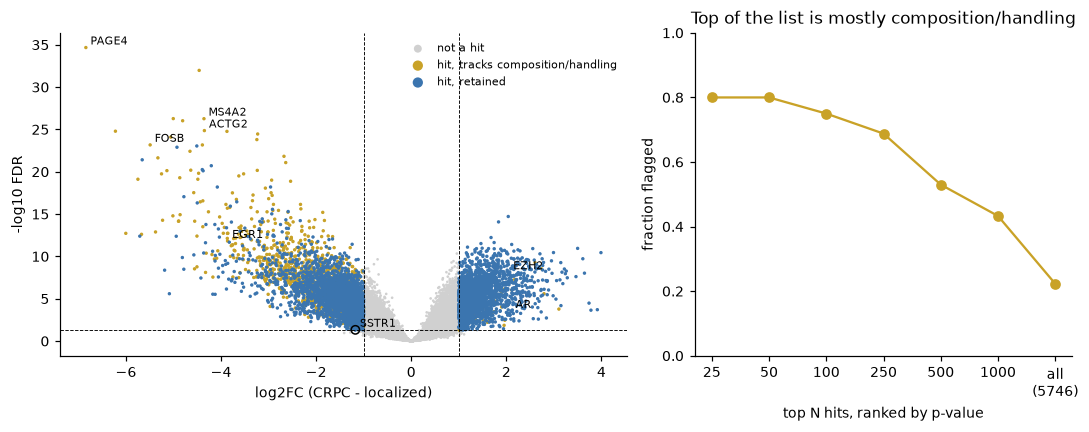

In [7]:
ranked = hits.sort_values("p")
top_n = [25, 50, 100, 250, 500, 1000, len(ranked)]
frac = [ranked.composition_flag.head(n).mean() for n in top_n]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
y = -np.log10(de.FDR.clip(lower=1e-300))
ax.scatter(de.log2FC, y, s=3, color="#d0d0d0", edgecolor="none", label="not a hit")
flag_hit = de.hit & de.composition_flag
keep_hit = de.hit & ~de.composition_flag
ax.scatter(de.log2FC[flag_hit], y[flag_hit], s=5, color="#c9a227", edgecolor="none", label="hit, tracks composition/handling")
ax.scatter(de.log2FC[keep_hit], y[keep_hit], s=5, color="#3b75af", edgecolor="none", label="hit, retained")
for g in ["PAGE4", "ACTG2", "FOSB", "EGR1", "MS4A2", "EZH2", "AR", "SSTR1"]:
    ax.annotate(g, (de.loc[g, "log2FC"], y[g]), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.scatter(de.loc["SSTR1", "log2FC"], y["SSTR1"], s=30, facecolor="none", edgecolor="k", linewidth=1)
ax.axhline(-np.log10(FDR_MAX), ls="--", lw=0.6, color="k")
for v in (-LFC_MIN, LFC_MIN):
    ax.axvline(v, ls="--", lw=0.6, color="k")
ax.set_xlabel("log2FC (CRPC - localized)")
ax.set_ylabel("-log10 FDR")
ax.legend(frameon=False, fontsize=7, loc="upper right", markerscale=3)

ax = axes[1]
ax.plot(range(len(top_n)), frac, marker="o", color="#c9a227")
ax.set_xticks(range(len(top_n)), [str(n) for n in top_n[:-1]] + [f"all\n({top_n[-1]})"])
ax.set_ylim(0, 1)
ax.set_xlabel("top N hits, ranked by p-value")
ax.set_ylabel("fraction flagged")
ax.set_title("Top of the list is mostly composition/handling")
fig.tight_layout()
fig.savefig(FIG / "02_volcano_composition.png", bbox_inches="tight")
plt.show()

### Pathway analysis

MSigDB Hallmark enrichment is run separately for unflagged up- and down-regulated hits using Enrichr. Cached result tables are used if the service is unavailable.


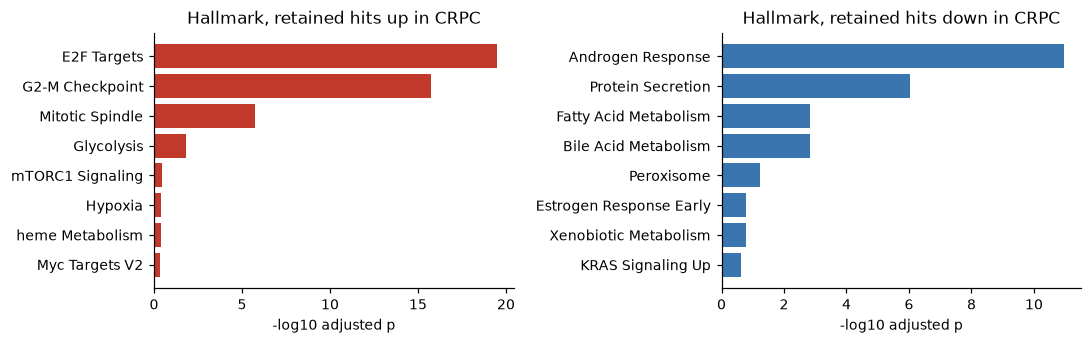

In [8]:
def hallmark(genes, tag):
    path = RES / f"hallmark_{tag}.csv"
    try:
        res = gp.enrichr(gene_list=list(genes), gene_sets="MSigDB_Hallmark_2020", organism="human", outdir=None).results
        res.to_csv(path, index=False)
    except Exception as e:
        print(f"Enrichr unavailable ({e}); using cached {path.name}")
        res = pd.read_csv(path)
    res["Term"] = res.Term.str.replace("Pperoxisome", "Peroxisome")  # typo in the Enrichr library
    return res.sort_values("Adjusted P-value")


kept = de[de.hit & ~de.composition_flag]
path_up = hallmark(kept.index[kept.log2FC > 0], "up_in_CRPC")
path_down = hallmark(kept.index[kept.log2FC < 0], "down_in_CRPC")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, df, title, color in [(axes[0], path_up, "up in CRPC", "#c0392b"), (axes[1], path_down, "down in CRPC", "#3b75af")]:
    d = df.head(8).iloc[::-1]
    ax.barh(d.Term, -np.log10(d["Adjusted P-value"]), color=color)
    ax.set_xlabel("-log10 adjusted p")
    ax.set_title(f"Hallmark, retained hits {title}")
fig.tight_layout()
fig.savefig(FIG / "03_hallmark_pathways.png", bbox_inches="tight")
plt.show()

## 5. Replication in SU2C/PCF 2019 mCRPC

The discovery comparison is broad, so I use the SU2C/PCF cohort (Abida et al., *PNAS* 2019) for a narrower analysis within metastatic CRPC: ARSI-exposed vs ARSI-naive biopsies.

- RNA-seq values: log2(FPKM + 1); one biopsy per patient.
- Model: `expression ~ ARSI exposure + biopsy site`.
- Genes: top 300 unflagged discovery hits plus prespecified SSTR1.
- Positive control: AR.


In [9]:
API = "https://www.cbioportal.org/api"
STUDY = "prad_su2c_2019"
PROFILE = f"{STUDY}_mrna_seq_fpkm_polya"


def cbio(path, body=None, **params):
    url = f"{API}/{path}"
    r = requests.post(url, json=body, params=params, timeout=300) if body is not None else requests.get(url, params=params, timeout=300)
    r.raise_for_status()
    return r.json()


kept = de[de.hit & ~de.composition_flag].copy()
kept["rank_score"] = kept.log2FC.abs().rank(pct=True) + (-np.log10(kept.FDR)).rank(pct=True)
to_test = kept.sort_values("rank_score", ascending=False).head(N_REPLICATE).index.tolist()
to_test += [g for g in PRESPECIFIED if g not in to_test]
CONTROLS = ["AR", "EZH2", "KLK3"]
fetch = list(dict.fromkeys(to_test + CONTROLS))

expr_cache, clin_cache = DATA / "su2c_polya_log2fpkm.csv", DATA / "su2c_clinical.csv"
if expr_cache.exists() and set(fetch) <= set(pd.read_csv(expr_cache, nrows=0).columns):
    su2c = pd.read_csv(expr_cache, index_col=0)
    clin = pd.read_csv(clin_cache, index_col=0)
else:
    genes = cbio("genes/fetch", body=fetch, geneIdType="HUGO_GENE_SYMBOL")
    entrez = {g["entrezGeneId"]: g["hugoGeneSymbol"] for g in genes}
    rows = cbio(f"molecular-profiles/{PROFILE}/molecular-data/fetch",
                body={"entrezGeneIds": list(entrez), "sampleListId": f"{STUDY}_polya"}, projection="SUMMARY")
    long = pd.DataFrame(rows)
    su2c = np.log2(long.pivot(index="sampleId", columns="entrezGeneId", values="value").astype(float) + 1)
    su2c.columns = [entrez[c] for c in su2c.columns]
    clin = pd.DataFrame(cbio(f"studies/{STUDY}/clinical-data", clinicalDataType="SAMPLE", projection="SUMMARY", pageSize=100000))
    clin = clin.pivot(index="sampleId", columns="clinicalAttributeId", values="value").join(
        long.drop_duplicates("sampleId").set_index("sampleId")["patientId"])
    su2c.to_csv(expr_cache)
    clin.to_csv(clin_cache)

print(f"{len(fetch)} genes requested, {su2c.shape[1]} found in SU2C (others are outdated array symbols)")

s = clin.loc[su2c.index, ["ABI_ENZA_EXPOSURE_STATUS", "TISSUE_SITE", "AR_SCORE", "NEPC_SCORE", "patientId"]].copy()
s = s[s.ABI_ENZA_EXPOSURE_STATUS.isin(["Naive", "Exposed", "On treatment"])]
s = s.sort_index().drop_duplicates("patientId")
s["arsi"] = (s.ABI_ENZA_EXPOSURE_STATUS != "Naive").astype(int)
s["site"] = s.TISSUE_SITE.where(s.TISSUE_SITE.isin(["Bone", "LN", "Liver"]), "Other")
print(pd.crosstab(s.site, s.arsi.map({0: "ARSI-naive", 1: "ARSI-exposed"}), margins=True))

304 genes requested, 249 found in SU2C (others are outdated array symbols)
arsi   ARSI-exposed  ARSI-naive  All
site                                
Bone             40          30   70
LN               58          54  112
Liver            21          17   38
Other            17          20   37
All             136         121  257


In [10]:
rep = []
for g in [c for c in su2c.columns if c in de.index]:
    d = s.join(su2c[g].rename("y")).dropna(subset=["y"])
    fit = smf.ols("y ~ arsi + C(site)", data=d).fit()
    rep.append({"gene": g, "su2c_beta_ARSI": fit.params["arsi"], "su2c_p": fit.pvalues["arsi"],
                "su2c_median_log2FPKM": d.y.median(), "su2c_n": len(d)})
rep = pd.DataFrame(rep).set_index("gene")

tested = rep.index.intersection(to_test)
rep.loc[tested, "su2c_FDR"] = multipletests(rep.loc[tested, "su2c_p"], method="fdr_bh")[1]
rep["same_direction"] = np.sign(rep.su2c_beta_ARSI) == np.sign(de.log2FC.reindex(rep.index))
rep["replicated"] = rep.same_direction & (rep.su2c_FDR < REPL_FDR)

print("positive control AR:", rep.loc["AR", ["su2c_beta_ARSI", "su2c_p"]].round(6).to_dict())
print(f"tested {len(tested)}; same direction {rep.loc[tested, 'same_direction'].mean():.0%}; "
      f"replicated at FDR < {REPL_FDR}: {rep.loc[tested, 'replicated'].sum()}")
rep.loc[tested].sort_values("su2c_p").head(15).round(4)

positive control AR: {'su2c_beta_ARSI': 1.218851, 'su2c_p': 2.7e-05}
tested 246; same direction 57%; replicated at FDR < 0.1: 6


,su2c_beta_ARSI,su2c_p,su2c_median_log2FPKM,su2c_n,su2c_FDR,same_direction,replicated
gene,,,,,,,
DPP4,-1.01,0,2.33,257,0.0026,True,True
ST6GALNAC1,-0.738,0,0.598,257,0.003,True,True
TRPM8,-1.15,0.0001,1.63,257,0.0041,True,True
SNTG2,-0.184,0.0005,0.0946,257,0.0313,True,True
TSPAN11,-0.366,0.0009,0.424,257,0.0459,True,True
AGBL2,-0.136,0.0024,0.188,257,0.0996,True,True
CHP2,-0.114,0.0039,0,257,0.138,True,False
HS3ST3A1,-0.136,0.0063,0.211,257,0.14,True,False
CCPG1,0.254,0.0063,3.48,257,0.14,False,False


## 6. UniProt annotation

Reviewed human UniProt entries are used to add subcellular location and broad protein class. These annotations support candidate review but do not establish druggability.


In [11]:
uniprot_cache = DATA / "uniprot_annotation.csv"


def uniprot_lookup(genes, batch=40):
    out = []
    for i in range(0, len(genes), batch):
        chunk = genes[i:i + batch]
        query = "(" + " OR ".join(f"gene_exact:{g}" for g in chunk) + ") AND organism_id:9606 AND reviewed:true"
        r = requests.get("https://rest.uniprot.org/uniprotkb/search", timeout=120,
                         params={"query": query, "format": "tsv", "size": 500,
                                 "fields": "accession,gene_primary,protein_name,keyword,cc_subcellular_location"})
        r.raise_for_status()
        out.append(pd.read_csv(io.StringIO(r.text), sep="\t"))
    df = pd.concat(out).rename(columns={"Entry": "uniprot", "Gene Names (primary)": "gene",
                                        "Protein names": "protein", "Keywords": "keywords",
                                        "Subcellular location [CC]": "location"})
    return df[df.gene.isin(genes)].drop_duplicates("gene").set_index("gene")


if uniprot_cache.exists() and set(tested) <= set(pd.read_csv(uniprot_cache).gene):
    uni = pd.read_csv(uniprot_cache, index_col="gene")
else:
    uni = uniprot_lookup(list(tested))
    uni.to_csv(uniprot_cache)


def protein_class(kw):
    kw = str(kw)
    if "G protein-coupled receptor" in kw:
        return "GPCR"
    if "Kinase" in kw:
        return "kinase"
    if "Ion channel" in kw:
        return "ion channel"
    if "Receptor" in kw and "DNA-binding" in kw:
        return "nuclear receptor"
    if "Receptor" in kw and "Transmembrane" in kw:
        return "membrane receptor"
    if any(k in kw for k in ["Protease", "Hydrolase", "Transferase", "Oxidoreductase", "Lyase", "Ligase", "Isomerase"]):
        return "enzyme"
    if "Transcription regulation" in kw:
        return "transcription regulator"
    if "Secreted" in kw:
        return "secreted"
    return "other"


uni["protein_class"] = uni.keywords.map(protein_class)
uni["cell_surface"] = uni.keywords.fillna("").str.contains("Cell membrane") & uni.keywords.fillna("").str.contains("Transmembrane")
print(f"annotated {len(uni)} of {len(tested)} genes")
uni.protein_class.value_counts()

annotated 246 of 246 genes


protein_class
other                      112
enzyme                      49
secreted                    41
transcription regulator     17
membrane receptor            9
GPCR                         6
ion channel                  5
kinase                       5
nuclear receptor             2
Name: count, dtype: int64

## 7. Candidate table

Candidates are grouped by simple rules rather than a learned score:

- **Tier 1:** discovery hit, not composition/handling flagged, same-direction SU2C result with FDR < 0.10.
- **Tier 2:** discovery hit, not flagged, tested in SU2C but not meeting the replication rule.

Flagged genes remain in the full differential-expression table but are excluded from the candidate table.


In [12]:
cand = (de.loc[tested, ["log2FC", "FDR", "composition_rho", "composition_driver"]]
        .rename(columns={"log2FC": "log2FC_GSE35988", "FDR": "FDR_GSE35988"})
        .join(rep[["su2c_beta_ARSI", "su2c_p", "su2c_FDR", "su2c_median_log2FPKM", "replicated"]])
        .join(uni[["uniprot", "protein_class", "cell_surface"]]))
cand["direction_in_CRPC"] = np.where(cand.log2FC_GSE35988 > 0, "up", "down")
cand["tier"] = np.where(cand.replicated, 1, 2)
cand["prespecified"] = cand.index.isin(PRESPECIFIED)
cand = cand.sort_values(["tier", "su2c_p"])
cols = ["tier", "direction_in_CRPC", "log2FC_GSE35988", "FDR_GSE35988", "su2c_beta_ARSI", "su2c_p", "su2c_FDR",
        "su2c_median_log2FPKM", "composition_rho", "protein_class", "cell_surface", "uniprot", "prespecified"]
cand[cols].to_csv(RES / "candidate_targets.csv", index_label="gene", float_format="%.4g")

print(cand.tier.value_counts().sort_index().to_string())
cand.loc[cand.tier == 1, cols].head(20).round(3)

tier
1      6
2    240


,tier,direction_in_CRPC,log2FC_GSE35988,FDR_GSE35988,su2c_beta_ARSI,su2c_p,su2c_FDR,su2c_median_log2FPKM,composition_rho,protein_class,cell_surface,uniprot,prespecified
gene,,,,,,,,,,,,,
DPP4,1,down,-4.78,0,-1.01,0,0.003,2.33,0.164,membrane receptor,True,P27487,False
ST6GALNAC1,1,down,-4.18,0,-0.738,0,0.003,0.598,0.208,enzyme,False,Q9NSC7,False
TRPM8,1,down,-5.19,0,-1.15,0,0.004,1.63,-0.159,ion channel,True,Q7Z2W7,False
SNTG2,1,down,-2.76,0,-0.185,0.001,0.031,0.095,0.042,other,False,Q9NY99,False
TSPAN11,1,down,-2.71,0,-0.366,0.001,0.046,0.424,0.416,other,False,A1L157,False
AGBL2,1,down,-2.73,0,-0.136,0.002,0.1,0.188,0.267,enzyme,False,Q5U5Z8,False


Six candidates meet the replication rule, all lower in both CRPC and ARSI-exposed tumors. Several are androgen-regulated, and the retained down-regulated set is enriched for Hallmark Androgen Response. The replicated signal therefore largely reflects suppression of AR-linked transcription under treatment pressure rather than a single new resistance mechanism.

## 8. SSTR1

SSTR1 was prespecified from my experimental work and is evaluated separately from the genome-wide ranking.


GSE35988: {'log2FC': -1.1752119292282692, 'p': 0.030530025381947344, 'FDR': 0.0468357108854242, 'composition_rho': 0.014591836734693876, 'composition_driver': 'early_response'}
SU2C (site-adjusted): {'su2c_beta_ARSI': -0.34303317589403914, 'su2c_p': 0.07661903282173198, 'su2c_median_log2FPKM': 1.245739032429285, 'su2c_n': 257.0}
unadjusted Mann-Whitney p: 0.0129
median log2(FPKM+1) by site and exposure:


status,ARSI-exposed,ARSI-naive
site,,
Bone,0.62,1.17
LN,1.23,2.09
Liver,1.57,1.34
Other,1.63,1.13


SSTR1 vs AR_SCORE: Spearman rho = 0.19, p = 0.0021
SSTR1 vs NEPC_SCORE: Spearman rho = -0.06, p = 0.32


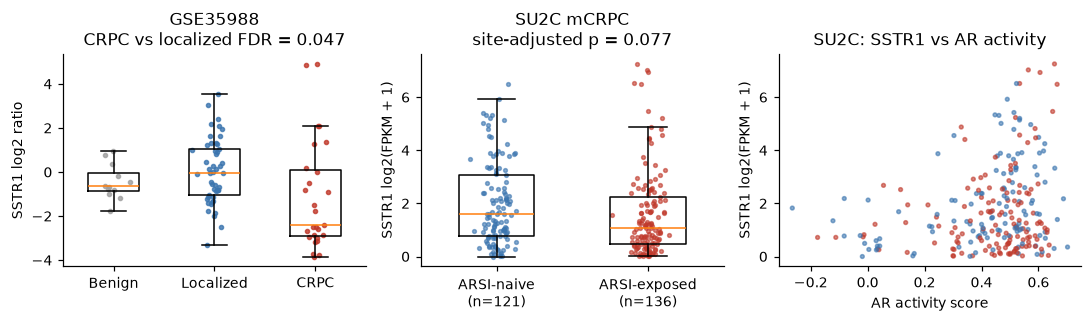

In [13]:
g = "SSTR1"
print("GSE35988:", de.loc[g, ["log2FC", "p", "FDR", "composition_rho", "composition_driver"]].to_dict())
print("SU2C (site-adjusted):", rep.loc[g, ["su2c_beta_ARSI", "su2c_p", "su2c_median_log2FPKM", "su2c_n"]].to_dict())

d = s.join(su2c[g].rename("SSTR1"))
d["status"] = d.arsi.map({0: "ARSI-naive", 1: "ARSI-exposed"})
print("unadjusted Mann-Whitney p:",
      round(stats.mannwhitneyu(d.SSTR1[d.arsi == 1], d.SSTR1[d.arsi == 0]).pvalue, 4))
print("median log2(FPKM+1) by site and exposure:")
display(d.pivot_table(index="site", columns="status", values="SSTR1", aggfunc="median").round(2))
for score in ["AR_SCORE", "NEPC_SCORE"]:
    r_, p_ = stats.spearmanr(d.SSTR1, d[score].astype(float), nan_policy="omit")
    print(f"SSTR1 vs {score}: Spearman rho = {r_:.2f}, p = {p_:.2g}")

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
order = ["Benign", "Localized", "CRPC"]
vals = [expr.loc[g, meta.index[meta.group == k]].dropna() for k in order]
axes[0].boxplot(vals, showfliers=False, widths=0.5)
for i, (k, v) in enumerate(zip(order, vals), start=1):
    axes[0].scatter(rng.normal(i, 0.06, len(v)), v, s=7, color=GROUP_COLORS[k], alpha=0.8)
axes[0].set_xticks([1, 2, 3], order)
axes[0].set_ylabel("SSTR1 log2 ratio")
axes[0].set_title(f"GSE35988\nCRPC vs localized FDR = {de.loc[g, 'FDR']:.3f}")

st = ["ARSI-naive", "ARSI-exposed"]
vals = [d.loc[d.status == k, "SSTR1"] for k in st]
axes[1].boxplot(vals, showfliers=False, widths=0.5)
for i, v in enumerate(vals, start=1):
    axes[1].scatter(rng.normal(i, 0.06, len(v)), v, s=6, color=["#3b75af", "#c0392b"][i - 1], alpha=0.6)
axes[1].set_xticks([1, 2], [f"{k}\n(n={len(v)})" for k, v in zip(st, vals)])
axes[1].set_ylabel("SSTR1 log2(FPKM + 1)")
axes[1].set_title(f"SU2C mCRPC\nsite-adjusted p = {rep.loc[g, 'su2c_p']:.3f}")

axes[2].scatter(d.AR_SCORE.astype(float), d.SSTR1, s=6, c=d.arsi.map({0: "#3b75af", 1: "#c0392b"}), alpha=0.6)
axes[2].set_xlabel("AR activity score")
axes[2].set_ylabel("SSTR1 log2(FPKM + 1)")
axes[2].set_title("SU2C: SSTR1 vs AR activity")
fig.tight_layout()
fig.savefig(FIG / "04_sstr1.png", bbox_inches="tight")
plt.show()

**Interpretation.** SSTR1 is lower in CRPC than in localized tumors (log2FC -1.18, FDR 0.047) and is not associated with the four composition/handling scores used here (max |rho| = 0.01). In SU2C, SSTR1 is lower in ARSI-exposed tumors by unadjusted comparison (p = 0.013); after adjustment for biopsy site, the effect remains negative but does not reach p < 0.05 (beta -0.34, p = 0.077). SSTR1 also correlates modestly with AR activity across mCRPC (rho 0.19, p = 0.002).

The public data are directionally consistent with the experimental observation, but they are not sufficient to establish causality or therapeutic relevance. Surface receptor abundance and perturbation experiments are the relevant next steps.


## 9. LLM reasoning check

As a secondary analysis, I converted results from this notebook into 35 questions. The model receives the cohort description and task-specific inputs but not the answer label.

| Task type | n | Reference answer |
|---|---:|---|
| `direction_prior` | 12 | GSE35988 differential-expression result |
| `composition` | 12 | composition/handling flag from section 4 |
| `arsi_exposure` | 8 | SU2C site-adjusted result |
| `open` | 3 | prespecified 0–2 author rubric |

`evaluation/run_claude.py` sends the tasks to the API and saves raw responses. Closed tasks are scored against the data-derived labels; open tasks are scored manually.


In [14]:
COHORT_GSE = ("GSE35988 (Grasso et al., Nature 2012): Agilent two-color arrays; localized prostate cancers from radical "
              "prostatectomy and metastatic castration-resistant prostate cancers (CRPC) collected at rapid autopsy.")
COHORT_SU2C = ("SU2C/PCF 2019 (Abida et al., PNAS 2019): RNA-seq of metastatic CRPC biopsies (bone, lymph node, liver, "
               "other). Comparison of patients previously or currently treated with abiraterone and/or enzalutamide "
               "versus ARSI-naive patients, adjusted for biopsy site.")
marker_genes = {g for v in SIGNATURES.values() for g in v}


def label(effect, p_or_fdr, cutoff, up, down):
    if p_or_fdr >= cutoff:
        return "no_significant_difference"
    return up if effect > 0 else down


tasks = []
for gene in ["AR", "EZH2", "AURKA", "KLK3", "FOLH1", "SSTR1", "SSTR2", "SST", "TFF3", "ESR1", "SRD5A2", "NR3C1"]:
    r = de.loc[gene]
    tasks.append({
        "task_type": "direction_prior", "gene": gene, "scoring": "auto",
        "question": f"{COHORT_GSE}\n\nWithout access to the data, predict how {gene} mRNA in metastatic CRPC compares with "
                    f"localized prostate cancer in this dataset.",
        "answer_options": "higher_in_CRPC|lower_in_CRPC|no_significant_difference",
        "reference_label": label(r.log2FC, r.FDR, FDR_MAX, "higher_in_CRPC", "lower_in_CRPC"),
        "evidence": f"log2FC={r.log2FC:.2f}; FDR={r.FDR:.2g}",
    })

pool = de[de.hit & ~de.index.isin(marker_genes) & ~de.index.str.startswith(("LOC", "C1orf", "C2orf", "C18orf"))]
comp_pos = pool[pool.composition_flag].sort_values("p").head(6)
comp_neg = pool[~pool.composition_flag & (pool.composition_rho < 0.3)].sort_values("p").head(6)
for gene, r in pd.concat([comp_pos, comp_neg]).sort_values("p").iterrows():
    direction = "higher" if r.log2FC > 0 else "lower"
    tasks.append({
        "task_type": "composition", "gene": gene, "scoring": "auto",
        "question": f"{COHORT_GSE}\n\n{gene} is {direction} in CRPC than in localized tumors (difference in mean log2 ratio "
                    f"{r.log2FC:.2f}, FDR {r.FDR:.1e}). Is the main explanation more likely a change within the cancer cells "
                    f"(tumor_intrinsic) or a difference in non-cancer cell content or tissue handling between surgical "
                    f"and autopsy samples (composition_or_handling)?",
        "answer_options": "tumor_intrinsic|composition_or_handling",
        "reference_label": "composition_or_handling" if r.composition_flag else "tumor_intrinsic",
        "evidence": f"max rho={r.composition_rho:.2f} ({r.composition_driver})",
    })

tier1 = cand[(cand.tier == 1) & ~cand.prespecified].head(3).index.tolist()
tier2 = cand[(cand.tier == 2) & ~cand.prespecified].sort_values("su2c_p", ascending=False).head(2).index.tolist()
for gene in dict.fromkeys(["AR", "SSTR1", "EZH2"] + tier1 + tier2):
    r = rep.loc[gene]
    tasks.append({
        "task_type": "arsi_exposure", "gene": gene, "scoring": "auto",
        "question": f"{COHORT_SU2C}\n\nWithout access to the data, predict how {gene} mRNA in ARSI-exposed tumors compares "
                    f"with ARSI-naive tumors.",
        "answer_options": "higher_after_ARSI|lower_after_ARSI|no_significant_difference",
        "reference_label": label(r.su2c_beta_ARSI, r.su2c_p, 0.05, "higher_after_ARSI", "lower_after_ARSI"),
        "evidence": f"beta={r.su2c_beta_ARSI:.2f}; p={r.su2c_p:.2g}",
    })

OPEN = [
    ("FOSB",
     f"{COHORT_GSE}\n\nFOSB, FOS and EGR1 are among the most strongly decreased genes in CRPC compared with localized tumors. "
     "What is the most likely explanation, and how would you check it in this dataset?",
     "2 = identifies immediate-early gene induction from surgical warm ischemia / handling in prostatectomy samples (vs "
     "autopsy) and proposes checking co-variation with an IEG score or tissue-handling metadata; 1 = gives a plausible "
     "biological or composition argument without the handling artifact; 0 = treats it as a resistance driver."),
    ("SSTR1",
     "Which clinically available drugs engage somatostatin receptor 1 (SSTR1), and how selective are they?",
     "2 = names pasireotide as the approved analog with meaningful SSTR1 affinity, states that octreotide and lanreotide "
     "bind SSTR1 weakly, and notes there is no approved SSTR1-selective agonist; 1 = partly correct; 0 = claims octreotide "
     "or lanreotide are SSTR1 agonists or invents a selective drug."),
    ("SSTR1",
     "SSTR1 mRNA is lower in ARSI-resistant prostate cancer. Propose the single most informative first experiment to test "
     "whether loss of SSTR1 contributes causally to enzalutamide resistance, including controls and the expected result.",
     "2 = isogenic gain- and loss-of-function in an ARSI-sensitive and a matched resistant model, enzalutamide dose "
     "response as readout, rescue or ligand-dependence control, falsifiable prediction; 1 = reasonable but missing "
     "controls or causal logic; 0 = correlative only or infeasible."),
]
for gene, q, rubric in OPEN:
    tasks.append({"task_type": "open", "gene": gene, "scoring": "manual_author", "question": q,
                  "answer_options": "", "reference_label": rubric, "evidence": ""})

tasks = pd.DataFrame(tasks)
tasks.insert(0, "task_id", [f"T{i:02d}" for i in range(1, len(tasks) + 1)])
tasks.to_csv(EVAL / "tasks.csv", index=False)
print(tasks.groupby("task_type").size().to_string())
tasks[["task_id", "task_type", "gene", "reference_label", "evidence"]].query("task_type != 'open'")

task_type
arsi_exposure       8
composition        12
direction_prior    12
open                3


,task_id,task_type,gene,reference_label,evidence
0,T01,direction_prior,AR,higher_in_CRPC,log2FC=2.10; FDR=0.00028
1,T02,direction_prior,EZH2,higher_in_CRPC,log2FC=2.05; FDR=7.5e-09
2,T03,direction_prior,AURKA,higher_in_CRPC,log2FC=1.93; FDR=1.4e-07
3,T04,direction_prior,KLK3,lower_in_CRPC,log2FC=-1.83; FDR=7.6e-08
4,T05,direction_prior,FOLH1,lower_in_CRPC,log2FC=-1.55; FDR=0.012
5,T06,direction_prior,SSTR1,lower_in_CRPC,log2FC=-1.18; FDR=0.047
6,T07,direction_prior,SSTR2,no_significant_difference,log2FC=0.33; FDR=0.25
7,T08,direction_prior,SST,no_significant_difference,log2FC=0.46; FDR=0.31
8,T09,direction_prior,TFF3,lower_in_CRPC,log2FC=-2.18; FDR=0.00052
9,T10,direction_prior,ESR1,lower_in_CRPC,log2FC=-4.20; FDR=1.9e-21


### Scoring

Closed tasks use exact-match accuracy. Open tasks use the rubric stored in `evaluation/tasks.csv`; manual scores and notes are preserved when this notebook is rerun. Stated model confidence is also used to calculate a Brier score.

This evaluation is exploratory and is intended to identify concrete failure modes rather than produce a general benchmark score.


answered by a fallback model after a refusal: 3 of 35 [{'task_id': 'T28', 'gene': 'DPP4', 'served_by': 'claude-opus-5'}, {'task_id': 'T34', 'gene': 'SSTR1', 'served_by': 'claude-opus-5'}, {'task_id': 'T35', 'gene': 'SSTR1', 'served_by': 'claude-opus-5'}]


n  accuracy  mean_confidence  brier
model           task_type                                            
claude-opus-5-5 arsi_exposure     8      0.75             0.53    0.2
                composition      12      0.67             0.65    0.2
                direction_prior  12      0.67             0.66   0.18

,count,mean
model,,
claude-opus-5-5,3,2


High-confidence errors (confidence >= 0.7):


,task_id,gene,task_type,answer,reference_label,evidence,confidence,rationale
4,T05,FOLH1,direction_prior,higher_in_CRPC,lower_in_CRPC,log2FC=-1.55; FDR=0.012,0.7,FOLH1 encodes PSMA. Its expression is represse...


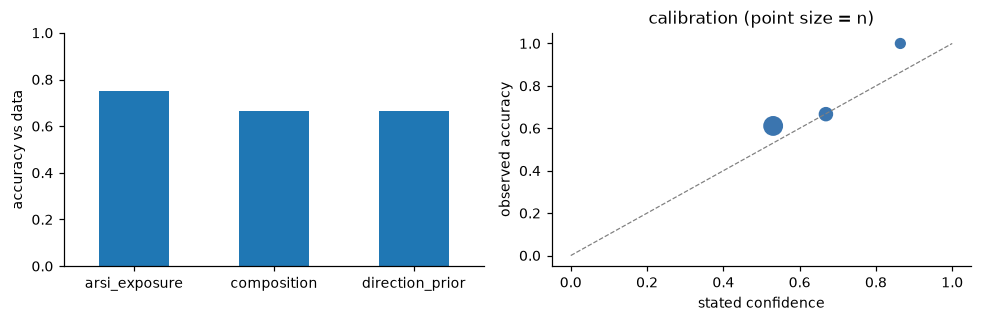

In [15]:
responses = sorted(EVAL.glob("responses_*.csv"))
if not responses:
    print("No model responses yet. From the repo root run:  python evaluation/run_claude.py")
else:
    resp = pd.concat([pd.read_csv(f) for f in responses], ignore_index=True)
    sc = tasks.merge(resp, on="task_id", how="inner")
    auto = sc.scoring == "auto"
    sc["correct"] = np.where(auto, (sc.answer == sc.reference_label).astype(float), np.nan)

    keep = ["task_id", "model", "author_score", "author_note"]
    if (EVAL / "scoring.csv").exists():
        old = pd.read_csv(EVAL / "scoring.csv")
        sc = sc.merge(old[[c for c in keep if c in old.columns]], on=["task_id", "model"], how="left")
    for c in ["author_score", "author_note"]:
        if c not in sc.columns:
            sc[c] = np.nan

    out_cols = ["task_id", "task_type", "gene", "model", "served_by", "answer", "reference_label", "evidence",
                "confidence", "correct", "author_score", "author_note", "rationale"]
    sc[out_cols].to_csv(EVAL / "scoring.csv", index=False)

    # a refusal on the requested model is answered by a fallback model; count those separately
    fell_back = sc[sc.served_by != sc.model]
    print(f"answered by a fallback model after a refusal: {len(fell_back)} of {len(sc)}",
          fell_back[["task_id", "gene", "served_by"]].to_dict("records"))

    a = sc[auto].copy()
    a["brier"] = (a.confidence - a.correct) ** 2
    summary = a.groupby(["model", "task_type"]).agg(n=("correct", "size"), accuracy=("correct", "mean"),
                                                     mean_confidence=("confidence", "mean"), brier=("brier", "mean"))
    display(summary.round(2))
    display(sc[sc.scoring == "manual_author"].groupby("model").author_score.agg(["count", "mean"]))

    print("High-confidence errors (confidence >= 0.7):")
    display(a[(a.correct == 0) & (a.confidence >= 0.7)][["task_id", "gene", "task_type", "answer", "reference_label",
                                                          "evidence", "confidence", "rationale"]])

    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    acc = a.groupby(["task_type", "model"]).correct.mean().unstack()
    acc.plot.bar(ax=axes[0], rot=0, legend=len(acc.columns) > 1)
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel("accuracy vs data")
    axes[0].set_xlabel("")
    bins = pd.cut(a.confidence, [0, 0.6, 0.8, 0.9, 1.0], include_lowest=True)
    cal = a.groupby(bins, observed=True).agg(conf=("confidence", "mean"), acc=("correct", "mean"), n=("correct", "size"))
    axes[1].plot([0, 1], [0, 1], ls="--", color="grey", lw=0.8)
    axes[1].scatter(cal.conf, cal.acc, s=cal.n * 8, color="#3b75af")
    axes[1].set_xlabel("stated confidence")
    axes[1].set_ylabel("observed accuracy")
    axes[1].set_title("calibration (point size = n)")
    fig.tight_layout()
    fig.savefig(FIG / "05_llm_evaluation.png", bbox_inches="tight")
    plt.show()

## 10. Limitations

1. The analyses are associative; causal claims require perturbation experiments.
2. CRPC vs localized disease confounds stage, metastatic site, prior therapy, and autopsy vs surgical collection. The marker-score filter addresses only part of this problem.
3. Marker averages are not a full deconvolution and can misclassify genes expressed across compartments.
4. Welch's t-test is intentionally simple; limma would be preferable for a formal microarray analysis and may move borderline genes.
5. Prior ARSI exposure in SU2C is not equivalent to ARSI resistance, and low-expression genes have limited power in FPKM data.
6. mRNA does not establish surface protein abundance or receptor function.
7. The LLM check is small and uses one run per task; its labels inherit the limitations of the underlying analyses.

## 11. Software versions


In [16]:
import sys, scipy, statsmodels, sklearn, matplotlib
versions = pd.Series({
    "python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "GEOparse": getattr(GEOparse, "__version__", "unknown"), "gseapy": gp.__version__, "requests": requests.__version__,
}, name="version")
versions.to_csv(RES / "software_versions.csv")
versions.to_frame()

,version
python,3.12.10
numpy,2.5.4
pandas,3.0.6
scipy,1.18.1
statsmodels,0.15.0
scikit-learn,1.9.1
matplotlib,3.11.2
GEOparse,2.0.4
gseapy,1.3.1
requests,2.34.2
